## K-Nearest Neighbors (KNN)
#### KNN is a supervised learning algorithm that predicts the class of a new data point based on the classes of its nearest neighbors.

It follows a simple idea:

Similar data points are likely to belong to the same class.

How KNN works
1. Choose the number of neighbors, K.
2. Calculate the distance between the new point and training points.
3. Select the K nearest neighbors.
4. Count their classes.
5. Assign the majority class.

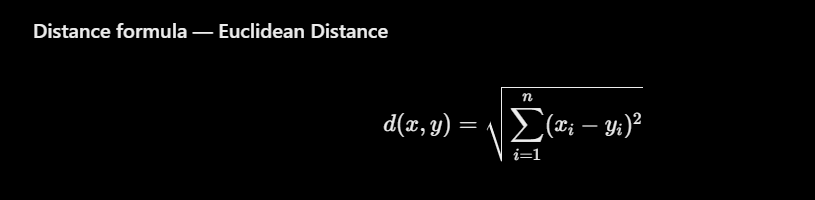

## Support Vector Machine (SVM)
#### SVM is a supervised learning algorithm that finds the best decision boundary to separate different classes.

It tries to maximize the margin between the closest data points of different classes.

Important concepts
- Hyperplane: Decision boundary separating classes.
- Margin: Distance between the hyperplane and the nearest points.
- Support Vectors: Data points closest to the decision boundary.
- Kernel: Helps SVM learn nonlinear decision boundaries.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
data = load_breast_cancer(as_frame=True)

df = data.frame

X = df.drop(columns="target")
y = df["target"]

print("Dataset shape:", df.shape)
print("Features:", X.shape)
print("Target:", y.shape)

Dataset shape: (569, 31)
Features: (569, 30)
Target: (569,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [4]:
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski",
        p=2
    ))
])

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

KNN Accuracy: 0.956140350877193


In [6]:
k_values = range(1, 21)

results = []

for k in k_values:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    model.fit(X_train, y_train)

    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)

    results.append({
        "K": k,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc
    })

knn_results = pd.DataFrame(results)

print(knn_results.sort_values(by="Test Accuracy", ascending=False).head(5))

     K  Train Accuracy  Test Accuracy
2    3        0.978022       0.982456
16  17        0.962637       0.982456
17  18        0.967033       0.982456
7    8        0.975824       0.973684
18  19        0.967033       0.973684


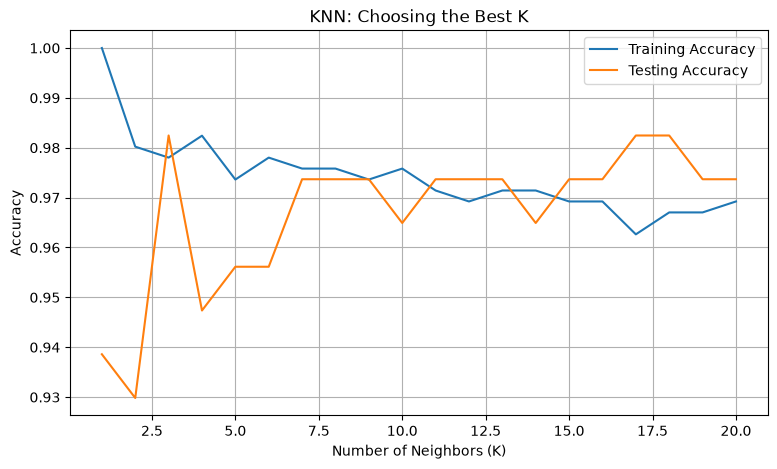

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(
    knn_results["K"],
    knn_results["Train Accuracy"],
    label="Training Accuracy"
)

plt.plot(
    knn_results["K"],
    knn_results["Test Accuracy"],
    label="Testing Accuracy"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN: Choosing the Best K")
plt.legend()
plt.grid()

plt.show()

In [8]:
svm_linear = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="linear",
        C=1.0
    ))
])

svm_linear.fit(X_train, y_train)

y_pred_linear = svm_linear.predict(X_test)

print(
    "Linear SVM Accuracy:",
    accuracy_score(y_test, y_pred_linear)
)

Linear SVM Accuracy: 0.9736842105263158


In [11]:
svm_rbf = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)

print(
    "RBF SVM Accuracy:",
    accuracy_score(y_test, y_pred_rbf)
)

RBF SVM Accuracy: 0.9824561403508771


In [9]:
kernels = ["linear", "poly", "rbf", "sigmoid"]

kernel_results = []

for kernel in kernels:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel=kernel,
            C=1.0
        ))
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    kernel_results.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y_test, predictions)
    })

kernel_df = pd.DataFrame(kernel_results)

print(kernel_df)

    Kernel  Accuracy
0   linear  0.973684
1     poly  0.912281
2      rbf  0.982456
3  sigmoid  0.929825


In [12]:
print("KNN Classification Report")
print(classification_report(y_test, y_pred_knn))

print("SVM Classification Report")
print(classification_report(y_test, y_pred_rbf))

KNN Classification Report
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

SVM Classification Report
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [13]:
print("KNN Confusion Matrix")
print(confusion_matrix(y_test, y_pred_knn))

print("\nSVM Confusion Matrix")
print(confusion_matrix(y_test, y_pred_rbf))

KNN Confusion Matrix
[[39  3]
 [ 2 70]]

SVM Confusion Matrix
[[41  1]
 [ 1 71]]


In [14]:
models = {
    "KNN": knn_model,
    "Linear SVM": svm_linear,
    "RBF SVM": svm_rbf
}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy",
        n_jobs=-1
    )

    print(f"\n{name}")
    print("CV Scores:", scores)
    print("Mean Accuracy:", scores.mean())


KNN
CV Scores: [0.94505495 1.         0.94505495 0.97802198 0.96703297]
Mean Accuracy: 0.9670329670329669

Linear SVM
CV Scores: [0.95604396 0.95604396 0.95604396 0.98901099 0.97802198]
Mean Accuracy: 0.9670329670329669

RBF SVM
CV Scores: [0.95604396 0.98901099 0.94505495 0.97802198 0.98901099]
Mean Accuracy: 0.9714285714285715
